# 高斯滤波作业

按顺序运行各个单元格。需要 NumPy、Matplotlib 和 OpenCV。图像使用 Matplotlib 自带的示例照片。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.cbook import get_sample_data

photo = plt.imread(get_sample_data("grace_hopper.jpg", asfileobj=False))
image = photo[::3, ::3, :3].mean(axis=2) / 255  # 缩小图片，转成灰度

## 2. 手动生成二维高斯核

以核的中心为坐标原点，按 $G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$ 计算权重。最后用权重总和归一化，所以计算时可以省去公共系数。$\sigma$ 是标准差，$\sigma^2$ 是方差。

OpenCV 的 `getGaussianKernel` 返回一维列向量，用它乘以自己的转置得到二维参考核。每行两张热力图共用一个色标。

5×5, σ=1，最大绝对误差 1.73e-18
15×15, σ=1，最大绝对误差 2.78e-17
15×15, σ=3，最大绝对误差 3.47e-18
25×25, σ=5，最大绝对误差 3.47e-18


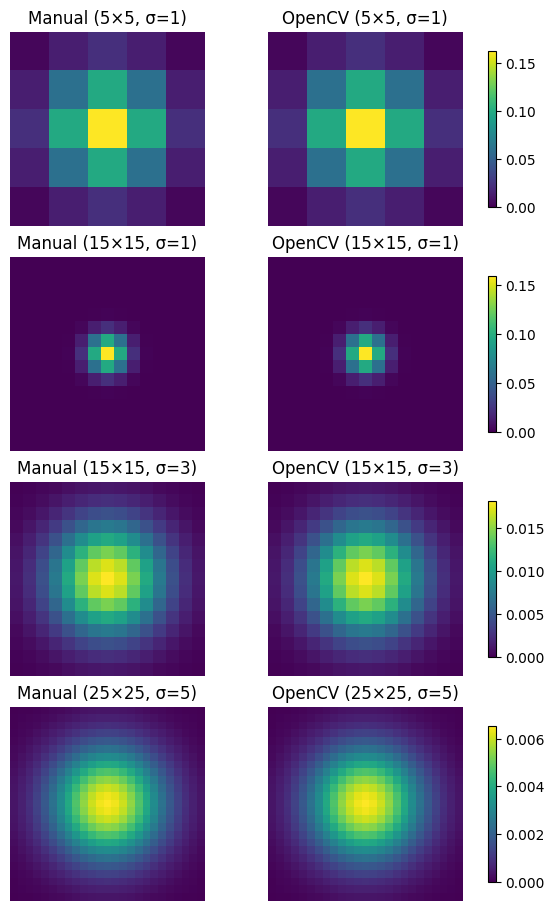

In [2]:
def gaussian_kernel(size, sigma):
    kernel = np.zeros((size, size))
    center = size // 2
    for row in range(size):
        for col in range(size):
            x = col - center
            y = row - center
            kernel[row, col] = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum() #归一化

# 每组是 (奇数边长, 正的 sigma)
parameters = [(5, 1.0), (15, 1.0), (15, 3.0), (25, 5.0)]
kernels = []

#返回两个对象 fig：整个画布、axes：画布上的子图对象数组
#采用自动布局
#len行2列，第一列为手动生成，第二列为库函数生成
fig, axes = plt.subplots(len(parameters), 2, figsize=(6, 9), layout="constrained")
for i, (size, sigma) in enumerate(parameters):
    manual = gaussian_kernel(size, sigma)
    kernels.append(manual)
    vector = cv2.getGaussianKernel(size, sigma)
    #矩阵乘法@，将库生成的一维高斯向量转变成二维的
    reference = vector @ vector.T
    #计算两种方法生成的高斯核之间的最大绝对误差
    error = np.abs(manual - reference).max()
    #`g` 是一种通用数值格式，可以避免不必要的尾随零
    #.2e科学计数法，保留2位小数
    print(f"{size}×{size}, σ={sigma:g}，最大绝对误差 {error:.2e}")

    #绘制高斯热力图
    for ax, values, name in zip(axes[i], [manual, reference], ["Manual", "OpenCV"]):
        #ax.imshow 是 Matplotlib 中的图像显示函数，可以将二维数组显示成图像，并返回一个图像对象
        #values代表需要显示的数据，camp代表颜色映射方案，这里用Matplotlib自带的
        #`vmin=0`设置颜色映射的最小值为 0。
        # `vmax=manual.max()`设置颜色映射的最大值为手动生成的高斯核中的最大值。
        plot = ax.imshow(values, cmap="viridis", vmin=0, vmax=manual.max())
        ax.set_title(f"{name} ({size}×{size}, σ={sigma:g})")
        #关闭子图坐标轴
        ax.axis("off")
    #Matplotlib 中添加颜色条的方法。颜色条的作用是说明不同颜色具体对应什么数值。
    #参数解释：
    #plot：指定颜色条所依据的图像对象。
    #ax=axes[i]：指定颜色条对应当前行的两个子图。
    #shrink=0.8：将颜色条长度缩小到原来的 80%。
    fig.colorbar(plot, ax=axes[i], shrink=0.8)

#显示的 Matplotlib 当前由 pyplot 管理的 Figure 画布及其内部所有绘图内容
plt.show()

热力图的颜色随权重变化。两种方法的最大绝对误差约为浮点舍入误差的量级。

## 3. 手动进行高斯模糊

先把原图放到全零数组中间。然后在每个像素处取出与核同样大小的窗口，将窗口和核逐项相乘后求和，得到该位置的新像素值。高斯核是中心对称的，翻转前后的权重相同。

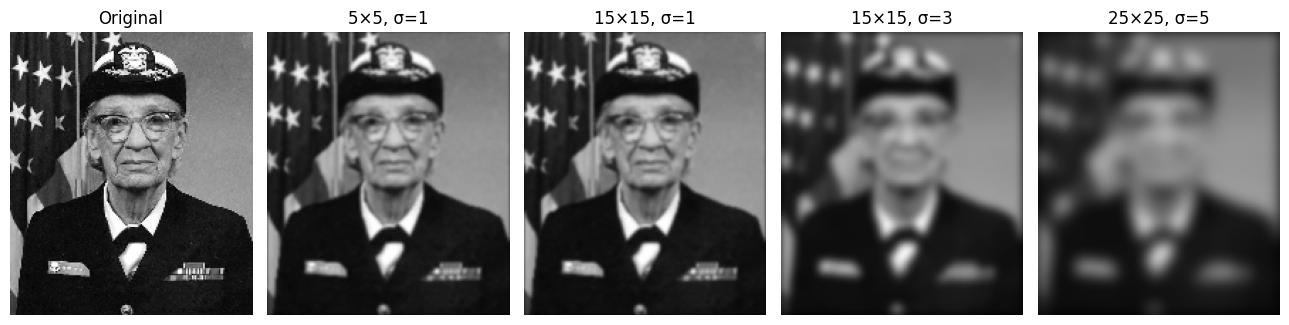

In [3]:
# 图像边缘填充函数（零填充）
# 参数pad：每个方向要填充的像素数量
def zero_pad(image, pad):
    height, width = image.shape
    #创建一个新的填充矩阵
    padded = np.zeros((height + 2 * pad, width + 2 * pad))
    #将原始图像放到新矩阵的中央位置，四周保留之前创建的 0
    #【start,end]左闭右开
    padded[pad:pad + height, pad:pad + width] = image
    return padded


#高斯模糊函数
def gaussian_blur(image, kernel):
    size = kernel.shape[0]  #高斯核的边长
    padded = zero_pad(image, size // 2) #调用边缘填充函数
    height, width = image.shape
    result = np.zeros((height, width))
    for row in range(height):
        for col in range(width):
            #取size * size的卷积窗口
            window = padded[row:row + size, col:col + size]
            result[row, col] = np.sum(window * kernel)
    return result

# 1表示画布有1行
fig, axes = plt.subplots(1, len(kernels) + 1, figsize=(13, 4))
# 采用灰度映射，灰度最小值为0，最大值为1
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
for i, (size, sigma) in enumerate(parameters):
    blurred = gaussian_blur(image, kernels[i])
    axes[i + 1].imshow(blurred, cmap="gray", vmin=0, vmax=1)
    axes[i + 1].set_title(f"{size}×{size}, σ={sigma:g}")
for ax in axes:
    ax.axis("off")
# 自动调整子图之间的间距
plt.tight_layout()
plt.show()

观察照片上的五官和衣领。$\sigma=1$ 时，$5×5$ 与 $15×15$ 的效果接近，因为离中心较远的权重很小。固定 $15×15$ 时，把 $\sigma$ 从 1 增加到 3，可以看到细节更模糊。补零也会让图像边缘略微变暗。

## 4. 手动实现两种边界填充

补零沿用第 3 题的函数。复制边缘时，先把原图放在中间，再复制第一行和最后一行，最后复制左右两列，顺带填好四个角。

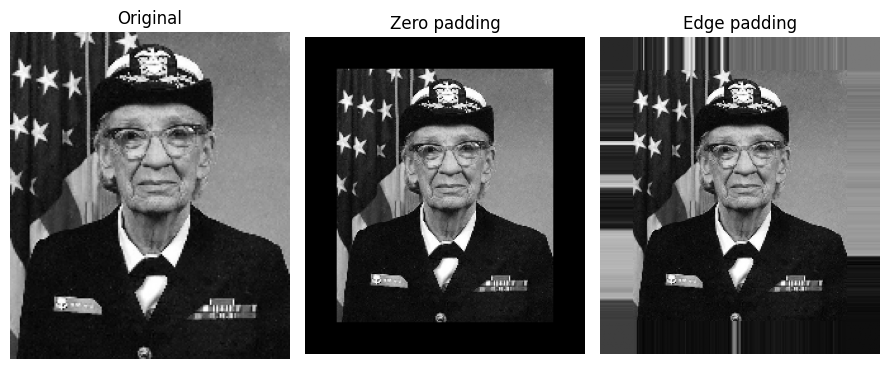

In [4]:
#边缘复制填充
def edge_pad(image, pad):
    height, width = image.shape
    padded = zero_pad(image, pad)
    #：pad省略起始位置，默认从0开始
    # pad + height : 省略终止位置，默认最后
    padded[:pad, pad:pad + width] = image[0, :] #上
    padded[pad + height:, pad:pad + width] = image[-1, :]   #-1表示最后  下
    #注意用pad : pad + 1而不是1,这样可以获得二维数组，虽然只有1列，但是相当于有行数个一维数组，每个一维数组都有一个元素，这样才能利用 NumPy 的广播机制，将这一列复制到左侧的多个列中
    padded[:, :pad] = padded[:, pad:pad + 1]
    padded[:, pad + width:] = padded[:, pad + width - 1:pad + width]
    return padded


pad = 25
#本题由于要观察边缘填充的效果，故显示padded而非image
images = [image, zero_pad(image, pad), edge_pad(image, pad)]
titles = ["Original", "Zero padding", "Edge padding"]

fig, axes = plt.subplots(1, 3, figsize=(9, 4))
for ax, pixels, title in zip(axes, images, titles):
    ax.imshow(pixels, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()